# Práctica 002: SVR para predecir ventas diarias

La portada (sección 0) la completa R4 con el título, los integrantes, el objetivo y el dataset. Este archivo tiene por ahora las secciones 1 a 3 (R1, Datos y EDA). R2, R3 y R4 agregan las secciones 4 a 12 en sus ramas.

## 1. Configuración

Aquí importamos las librerías, fijamos las rutas y la semilla (`SEED = 42`, una decisión cerrada del plan) y registramos las versiones, para que cualquiera del equipo pueda reproducir los resultados. `guardar()` deja todas las figuras en `resultados/figuras/` con `dpi=150`.

In [1]:
import platform
import random
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from matplotlib.patches import Patch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

RUTA_DATOS = Path("datos/ventas_features.csv")
RUTA_FIGURAS = Path("resultados/figuras")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 12})


def guardar(fig, nombre):
    """Guarda la figura en resultados/figuras/ con dpi=150."""
    fig.savefig(RUTA_FIGURAS / nombre, dpi=150, bbox_inches="tight")


pd.DataFrame(
    {
        "componente": ["Python", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "semilla (SEED)"],
        "versión": [
            platform.python_version(), pd.__version__, np.__version__,
            sklearn.__version__, matplotlib.__version__, sns.__version__, SEED,
        ],
    }
).set_index("componente")

,versión
componente,
Python,3.13.18
pandas,3.0.5
numpy,2.5.3
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
semilla (SEED),42


## 2. Datos y EDA mínimo

Trabajamos con `ventas_features.csv`, el dataset de la práctica 001: ventas diarias de 10 productos de una tienda de barrio durante 60 días (del 1 de enero al 1 de marzo de 2022), con variables de calendario, rezagos de ventas (*lags*), stock y caducidad. Lo que queremos predecir es `cantidad_vendida`, que es continua (unidades por día). Por eso usamos SVR, que es regresión, y no una clasificación artificial.

### 2.1 Carga y validación

Cargamos el CSV con `parse_dates` para que `fecha_venta` sea una fecha de verdad, lo que permite ordenar y dividir por tiempo, y lo ordenamos por fecha y producto. Después comprobamos con `assert` que el archivo es el esperado: 600 filas (10 productos por 60 días), sin duplicados y con rangos coherentes en las variables de calendario.

In [2]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["fecha_venta"])
df = df.sort_values(["fecha_venta", "product_id"]).reset_index(drop=True)

N_PRODUCTOS, N_DIAS = 10, 60
assert df.shape == (N_PRODUCTOS * N_DIAS, 22)
assert df["product_id"].nunique() == N_PRODUCTOS
assert (df.groupby("product_id")["fecha_venta"].nunique() == N_DIAS).all()
assert not df.duplicated(["product_id", "fecha_venta"]).any()

RANGOS_VALIDOS = {
    "mes": (1, 12), "dia_del_mes": (1, 31), "dia_semana": (0, 6),
    "es_fin_de_semana": (0, 1), "es_feriado": (0, 1), "semana_del_periodo": (1, 9),
    "cantidad_vendida": (1, np.inf), "stock_en_momento": (0, np.inf), "dias_para_expirar": (0, np.inf),
}
for columna, (minimo, maximo) in RANGOS_VALIDOS.items():
    assert df[columna].between(minimo, maximo).all(), f"{columna} fuera de rango"

def extremo(serie, funcion):
    """Mínimo o máximo legible; 'n/a' para columnas de texto, donde no tiene sentido."""
    if pd.api.types.is_datetime64_any_dtype(serie):
        return str(funcion(serie).date())
    if pd.api.types.is_numeric_dtype(serie):
        return f"{funcion(serie):g}"
    return "n/a"


pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "valores distintos": df.nunique(),
        "mínimo": [extremo(df[c], pd.Series.min) for c in df.columns],
        "máximo": [extremo(df[c], pd.Series.max) for c in df.columns],
    }
)

,tipo,nulos,valores distintos,mínimo,máximo
product_id,str,0,10,n/a,n/a
nombre,str,0,10,n/a,n/a
categoria,str,0,6,n/a,n/a
unidad,str,0,5,n/a,n/a
fecha_venta,datetime64[us],0,60,2022-01-01,2022-03-01
anio,int64,0,1,2022,2022
mes,int64,0,3,1,3
dia_del_mes,int64,0,31,1,31
dia_semana,int64,0,7,0,6
nombre_dia,str,0,7,n/a,n/a


### 2.2 Valores nulos

Hay nulos en tres variables y todos vienen de lo mismo: son rezagos que miran días anteriores, y los primeros días de cada producto no tienen pasado.

- `ventas_dia_anterior`: falta el día 1 de cada producto (10 nulos).
- `promedio_movil_7d`: también falta el día 1, porque no hay días previos que promediar (10 nulos).
- `ventas_hace_7_dias`: faltan los primeros 7 días de cada producto (70 nulos).

La celda comprueba con `assert` que los nulos están exactamente en esas posiciones, es decir, que no son errores al azar, y dibuja el mapa de nulos con una fila por producto y una columna por día.

,nulos,% del total,origen
ventas_dia_anterior,10,1.7,Día 1 de cada producto (sin día previo)
ventas_hace_7_dias,70,11.7,Días 1 a 7 de cada producto (sin ventas de hac...
promedio_movil_7d,10,1.7,Día 1 de cada producto (sin días previos para ...


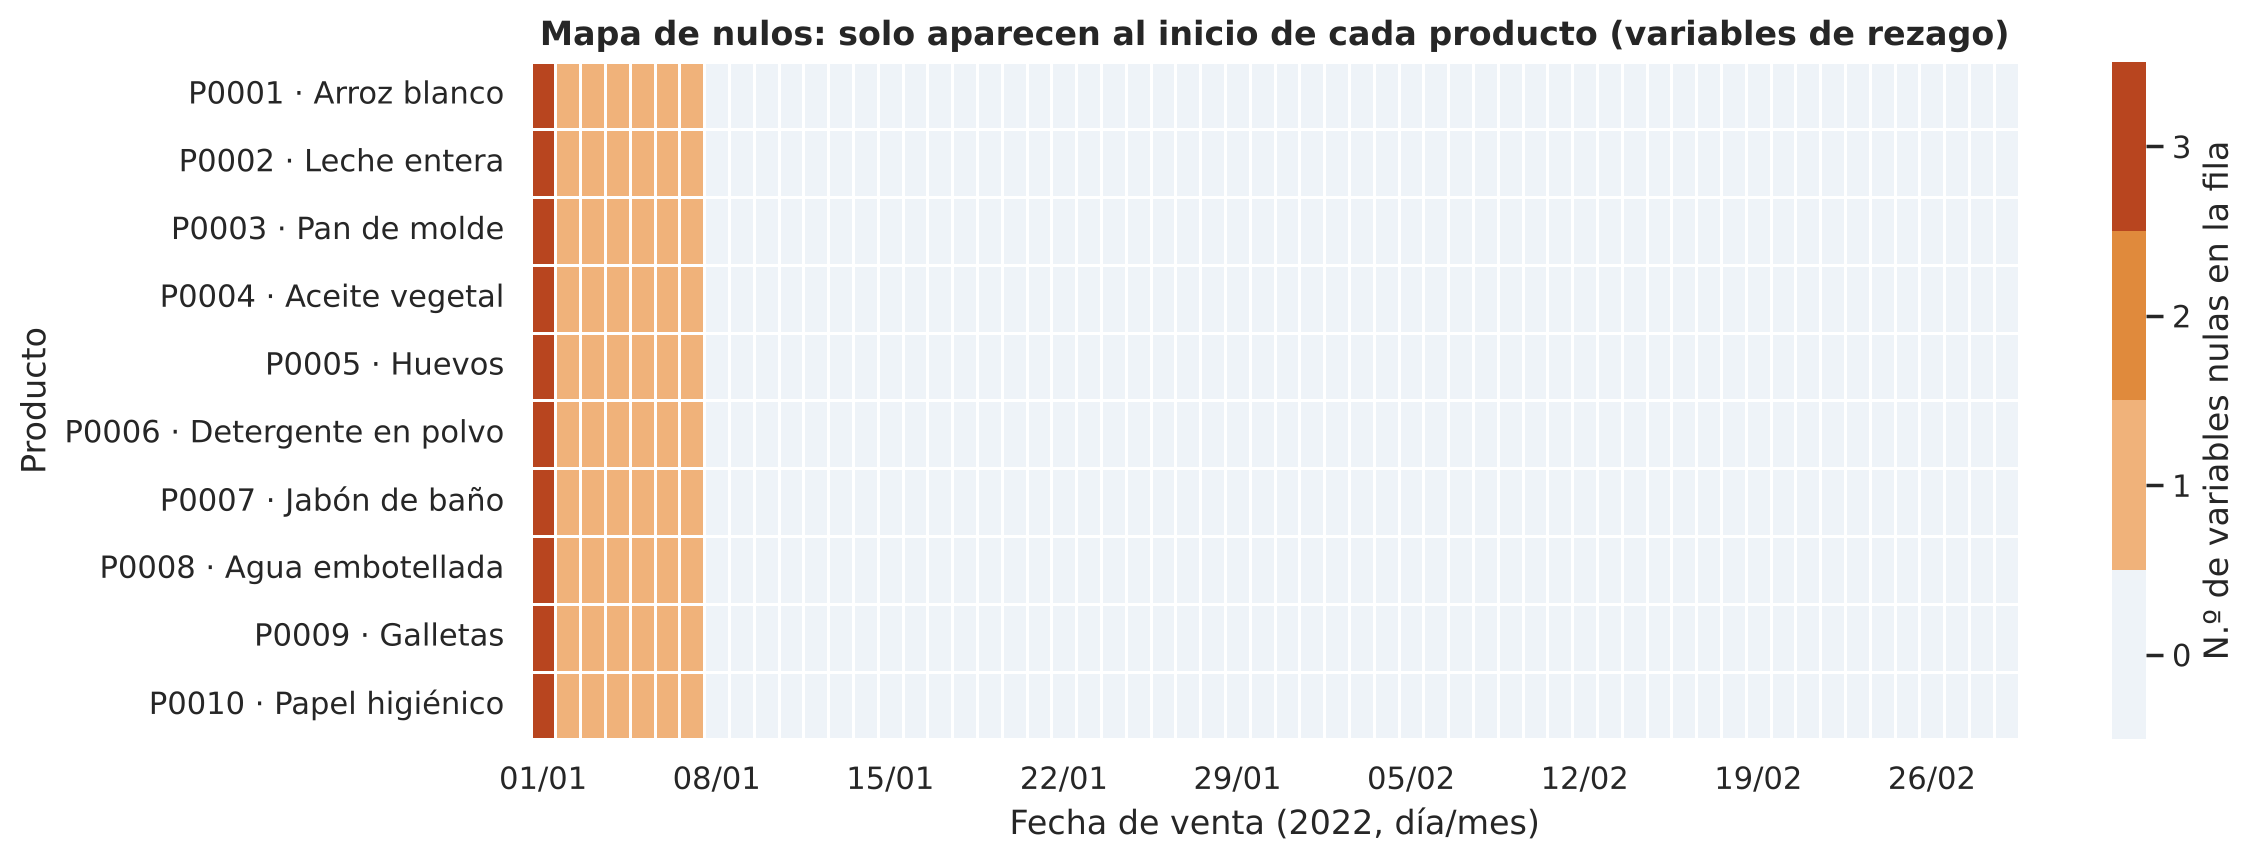

In [3]:
COLS_LAG = ["ventas_dia_anterior", "ventas_hace_7_dias", "promedio_movil_7d"]
indice_dia = (df["fecha_venta"] - df["fecha_venta"].min()).dt.days  # 0 = primer día

assert df["ventas_dia_anterior"].isna().eq(indice_dia == 0).all()
assert df["promedio_movil_7d"].isna().eq(indice_dia == 0).all()
assert df["ventas_hace_7_dias"].isna().eq(indice_dia < 7).all()
assert df.drop(columns=COLS_LAG).notna().all().all()

nulos = df[COLS_LAG].isna().sum().rename("nulos").to_frame()
nulos["% del total"] = (nulos["nulos"] / len(df) * 100).round(1)
nulos["origen"] = [
    "Día 1 de cada producto (sin día previo)",
    "Días 1 a 7 de cada producto (sin ventas de hace 7 días)",
    "Día 1 de cada producto (sin días previos para promediar)",
]
display(nulos)

etiquetas_producto = (
    df.drop_duplicates("product_id").set_index("product_id")["nombre"].pipe(lambda s: s.index + " · " + s)
)
mapa_nulos = (
    df.assign(n_nulos=df[COLS_LAG].isna().sum(axis=1))
    .pivot(index="product_id", columns="fecha_venta", values="n_nulos")
)

fig, ax = plt.subplots(figsize=(12, 4.4))
sns.heatmap(
    mapa_nulos, ax=ax, cmap=matplotlib.colors.ListedColormap(["#eef3f8", "#f0b27a", "#e08a3c", "#b8451f"]),
    vmin=-0.5, vmax=3.5, linewidths=0.4, linecolor="white",
    cbar_kws={"ticks": [0, 1, 2, 3], "label": "N.º de variables nulas en la fila"},
)
ax.set_yticks(np.arange(len(mapa_nulos)) + 0.5)
ax.set_yticklabels([etiquetas_producto[p] for p in mapa_nulos.index], rotation=0)
paso = 7
ax.set_xticks(np.arange(0, N_DIAS, paso) + 0.5)
ax.set_xticklabels([f.strftime("%d/%m") for f in mapa_nulos.columns[::paso]], rotation=0)
ax.set_xlabel("Fecha de venta (2022, día/mes)")
ax.set_ylabel("Producto")
ax.set_title("Mapa de nulos: solo aparecen al inicio de cada producto (variables de rezago)")
guardar(fig, "eda_nulos.png")
plt.show()

Decidimos eliminar las filas con nulos (`dropna`) en lugar de imputarlas. Rellenar un rezago con la media o con ceros inventaría ventas que nunca ocurrieron y distorsionaría justo las variables más informativas. Perdemos 70 filas (los primeros 7 días de cada producto) y quedamos con 530 registros útiles, que siguen siendo 53 días completos por producto. El `dropna` se aplica en la sección 3.2.

### 2.3 Distribución del target

Antes de modelar conviene ver cómo es `cantidad_vendida`: su rango, si es simétrica y cuánto cambia según el día de la semana.

,count,mean,std,min,25%,50%,75%,max,asimetría
cantidad_vendida,600.0,151.2,57.8,67.0,110.0,140.5,172.0,411.0,1.43


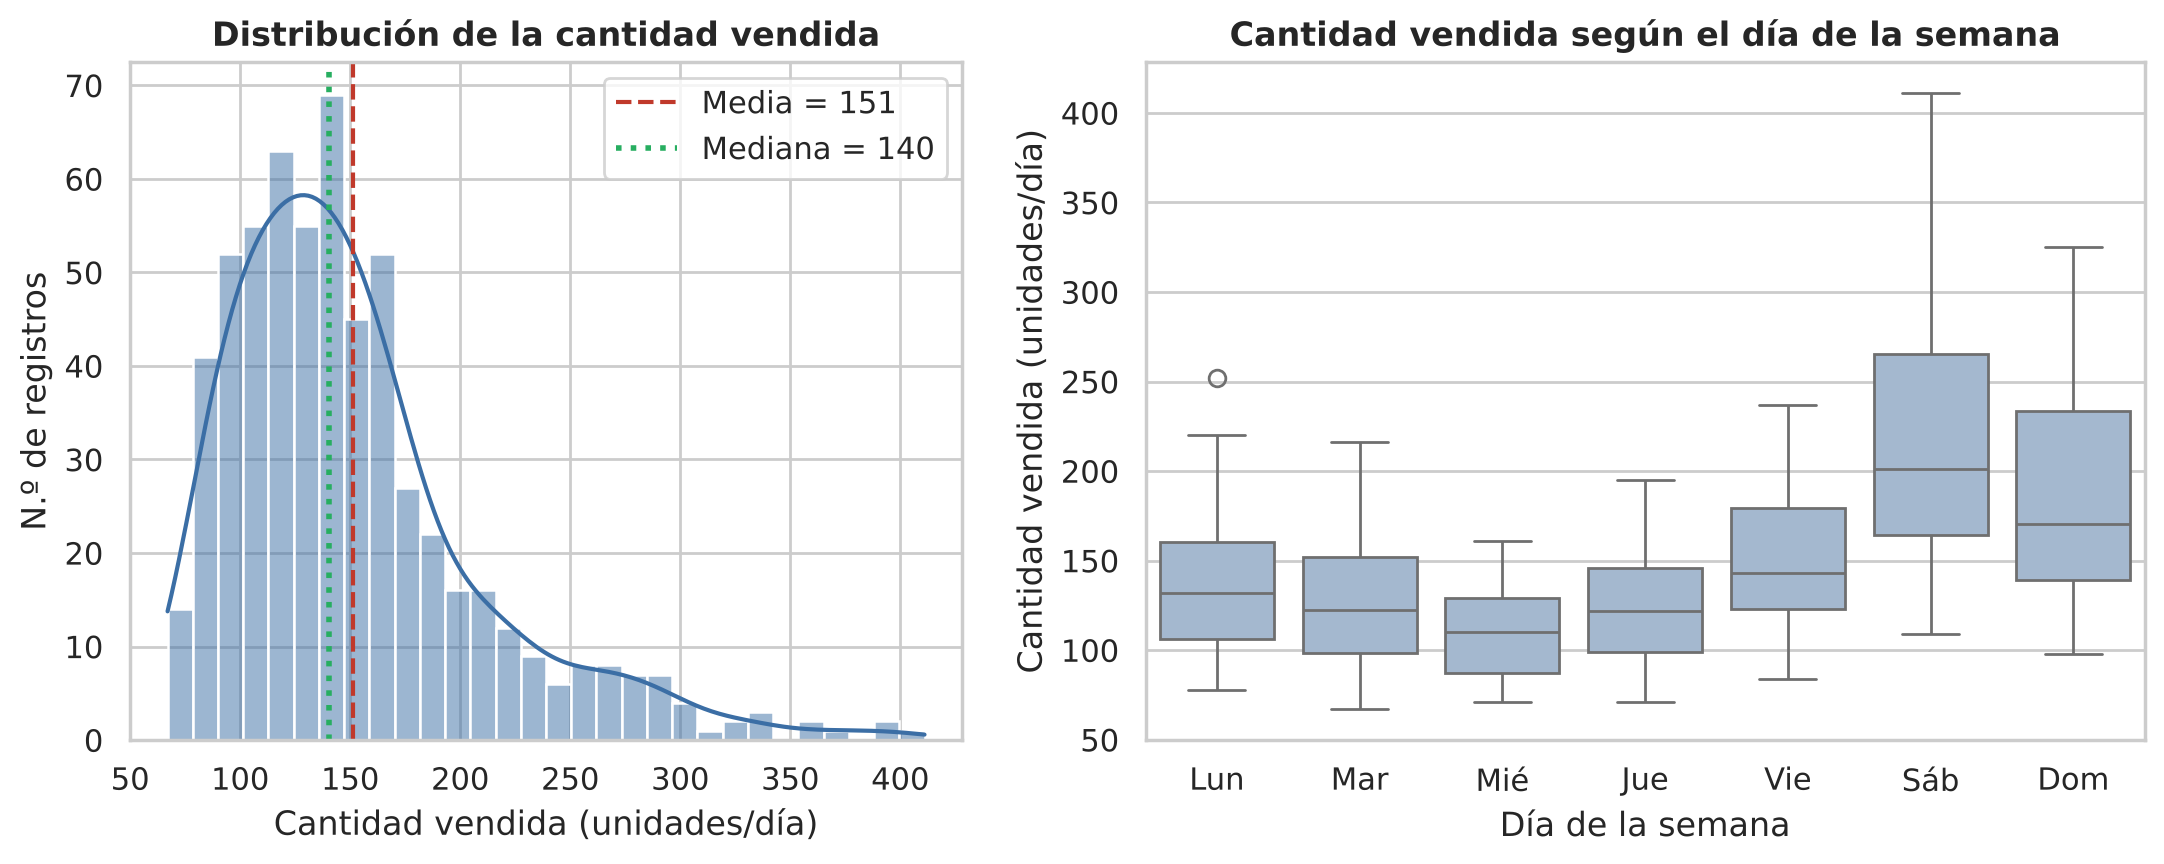

In [4]:
y_crudo = df["cantidad_vendida"]
resumen_target = y_crudo.describe().round(1).to_frame("cantidad_vendida").T
resumen_target["asimetría"] = round(y_crudo.skew(), 2)
display(resumen_target)

DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})

sns.histplot(y_crudo, bins=30, kde=True, color="#3b6ea5", ax=ejes[0])
ejes[0].axvline(y_crudo.mean(), color="#c0392b", ls="--", label=f"Media = {y_crudo.mean():.0f}")
ejes[0].axvline(y_crudo.median(), color="#27ae60", ls=":", lw=2, label=f"Mediana = {y_crudo.median():.0f}")
ejes[0].set(title="Distribución de la cantidad vendida", xlabel="Cantidad vendida (unidades/día)", ylabel="N.º de registros")
ejes[0].legend()

sns.boxplot(data=df, x="dia_semana", y="cantidad_vendida", color="#9db8d6", ax=ejes[1])
ejes[1].set_xticks(range(7))
ejes[1].set_xticklabels(DIAS)
ejes[1].set(title="Cantidad vendida según el día de la semana", xlabel="Día de la semana", ylabel="Cantidad vendida (unidades/día)")

guardar(fig, "eda_distribucion.png")
plt.show()

Interpretación: las ventas van de 67 a 411 unidades por día, con media 151 y mediana 140. La media queda por encima de la mediana porque hay cola hacia la derecha (asimetría de 1,4 aprox.): pocos días con ventas muy altas. Por día de la semana, sábado y domingo venden más (medianas de unos 200 y 170, contra 110 a 145 de lunes a viernes) y el miércoles es el día más bajo. Por eso esperamos que `dia_semana` y `es_fin_de_semana` aporten, y por eso el target se escala dentro del pipeline (R2): sin escalarlo, un `epsilon` de 0,1 sería minúsculo frente a ventas de cientos de unidades.

### 2.4 Ventas por categoría y producto

Comparamos el nivel de ventas entre categorías y productos. Las unidades cambian de un producto a otro (kg, litros, paquetes), así que comparamos niveles y patrones y no sumamos productos entre sí.

,productos,filas,media,desv_est,minimo,maximo
categoria,,,,,,
Bebidas,1,60,212.2,68.1,125,394
Snacks,1,60,199.5,67.6,119,411
Alimentos,5,300,150.0,48.7,71,389
Cuidado personal,1,60,123.6,27.5,80,179
Hogar,1,60,116.9,30.6,71,211
Limpieza,1,60,109.9,33.7,67,233


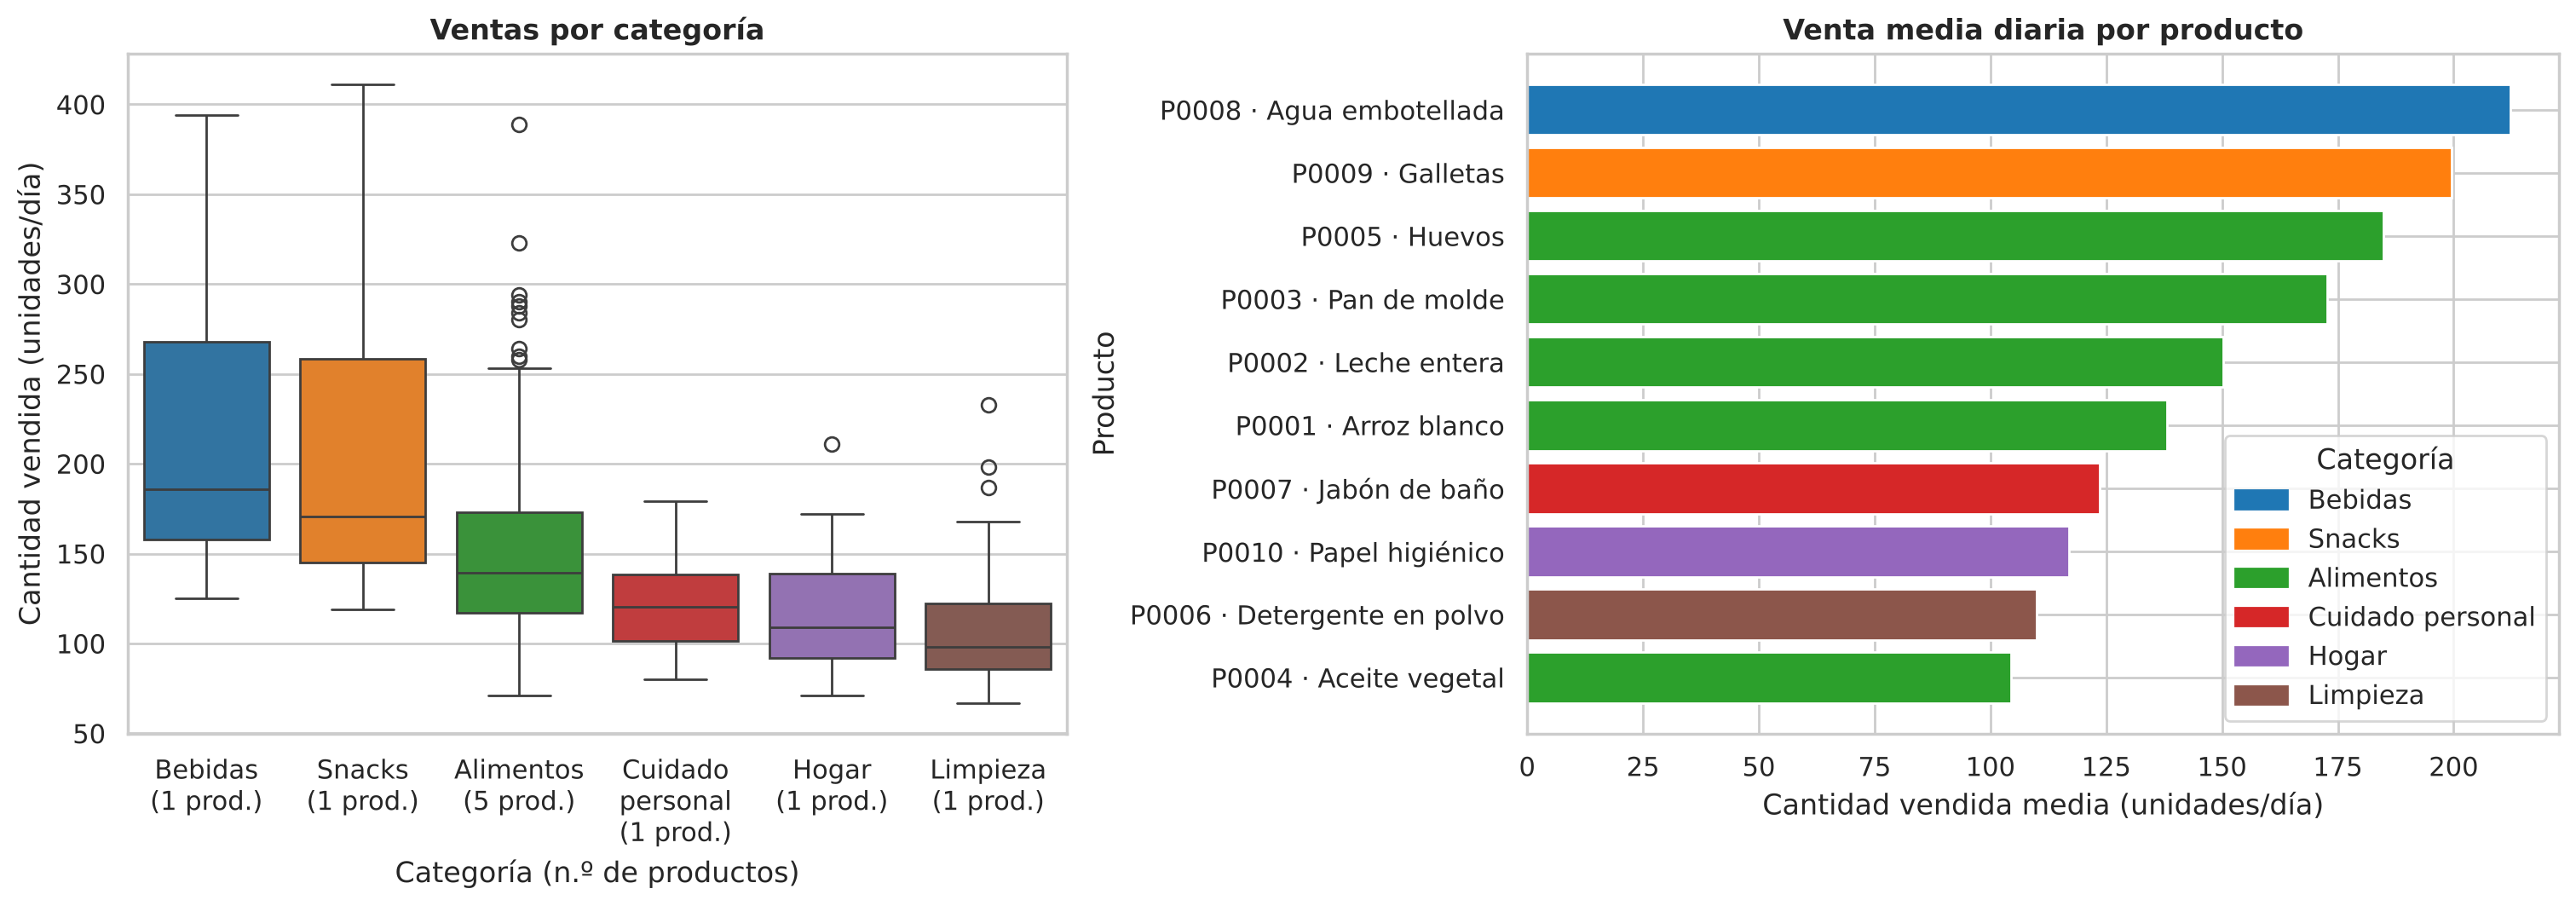

In [5]:
ORDEN_CAT = df.groupby("categoria")["cantidad_vendida"].mean().sort_values(ascending=False).index.tolist()
PALETA = dict(zip(ORDEN_CAT, sns.color_palette("tab10", len(ORDEN_CAT))))

por_categoria = (
    df.groupby("categoria")
    .agg(
        productos=("product_id", "nunique"), filas=("cantidad_vendida", "size"),
        media=("cantidad_vendida", "mean"), desv_est=("cantidad_vendida", "std"),
        minimo=("cantidad_vendida", "min"), maximo=("cantidad_vendida", "max"),
    )
    .loc[ORDEN_CAT]
    .round(1)
)
display(por_categoria)

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.1]}, layout="constrained")

sns.boxplot(data=df, x="categoria", y="cantidad_vendida", order=ORDEN_CAT, hue="categoria", palette=PALETA, legend=False, ax=ejes[0])
ejes[0].set_xticks(range(len(ORDEN_CAT)))
ejes[0].set_xticklabels([f"{c.replace(' ', chr(10))}\n({por_categoria.loc[c, 'productos']} prod.)" for c in ORDEN_CAT])
ejes[0].set(title="Ventas por categoría", xlabel="Categoría (n.º de productos)", ylabel="Cantidad vendida (unidades/día)")

por_producto = (
    df.groupby(["product_id", "nombre", "categoria"], as_index=False)["cantidad_vendida"].mean().sort_values("cantidad_vendida")
)
ejes[1].barh(por_producto["product_id"] + " · " + por_producto["nombre"], por_producto["cantidad_vendida"],
             color=por_producto["categoria"].map(PALETA))
ejes[1].set(title="Venta media diaria por producto", xlabel="Cantidad vendida media (unidades/día)", ylabel="Producto")
ejes[1].legend(handles=[Patch(color=PALETA[c], label=c) for c in ORDEN_CAT], title="Categoría", loc="lower right")

guardar(fig, "eda_categoria.png")
plt.show()

Interpretación: el nivel de ventas cambia mucho entre productos. Agua embotellada (Bebidas, unos 212) y Galletas (Snacks, unos 200) venden casi el doble que Detergente en polvo y Aceite vegetal (entre 105 y 110). La dispersión también cambia: Bebidas y Snacks varían bastante más (desviación estándar de unos 68) que Cuidado personal (unos 28). Además hay un desbalance: Alimentos reúne 5 productos (300 filas) y cada una de las otras 5 categorías tiene un solo producto (60 filas), así que `categoria` y `product_id` se solapan casi por completo (ver 3.7). La identidad del producto explica buena parte del nivel de ventas, por eso `product_id` es una predictora importante y por eso no tiene sentido predecir `categoria` (decisión 3 en 3.8).

### 2.5 Evolución temporal

Graficamos la venta media diaria a lo largo del tiempo, con los fines de semana sombreados en gris y los feriados con una línea roja, para ver la tendencia, la estacionalidad semanal y los eventos especiales.

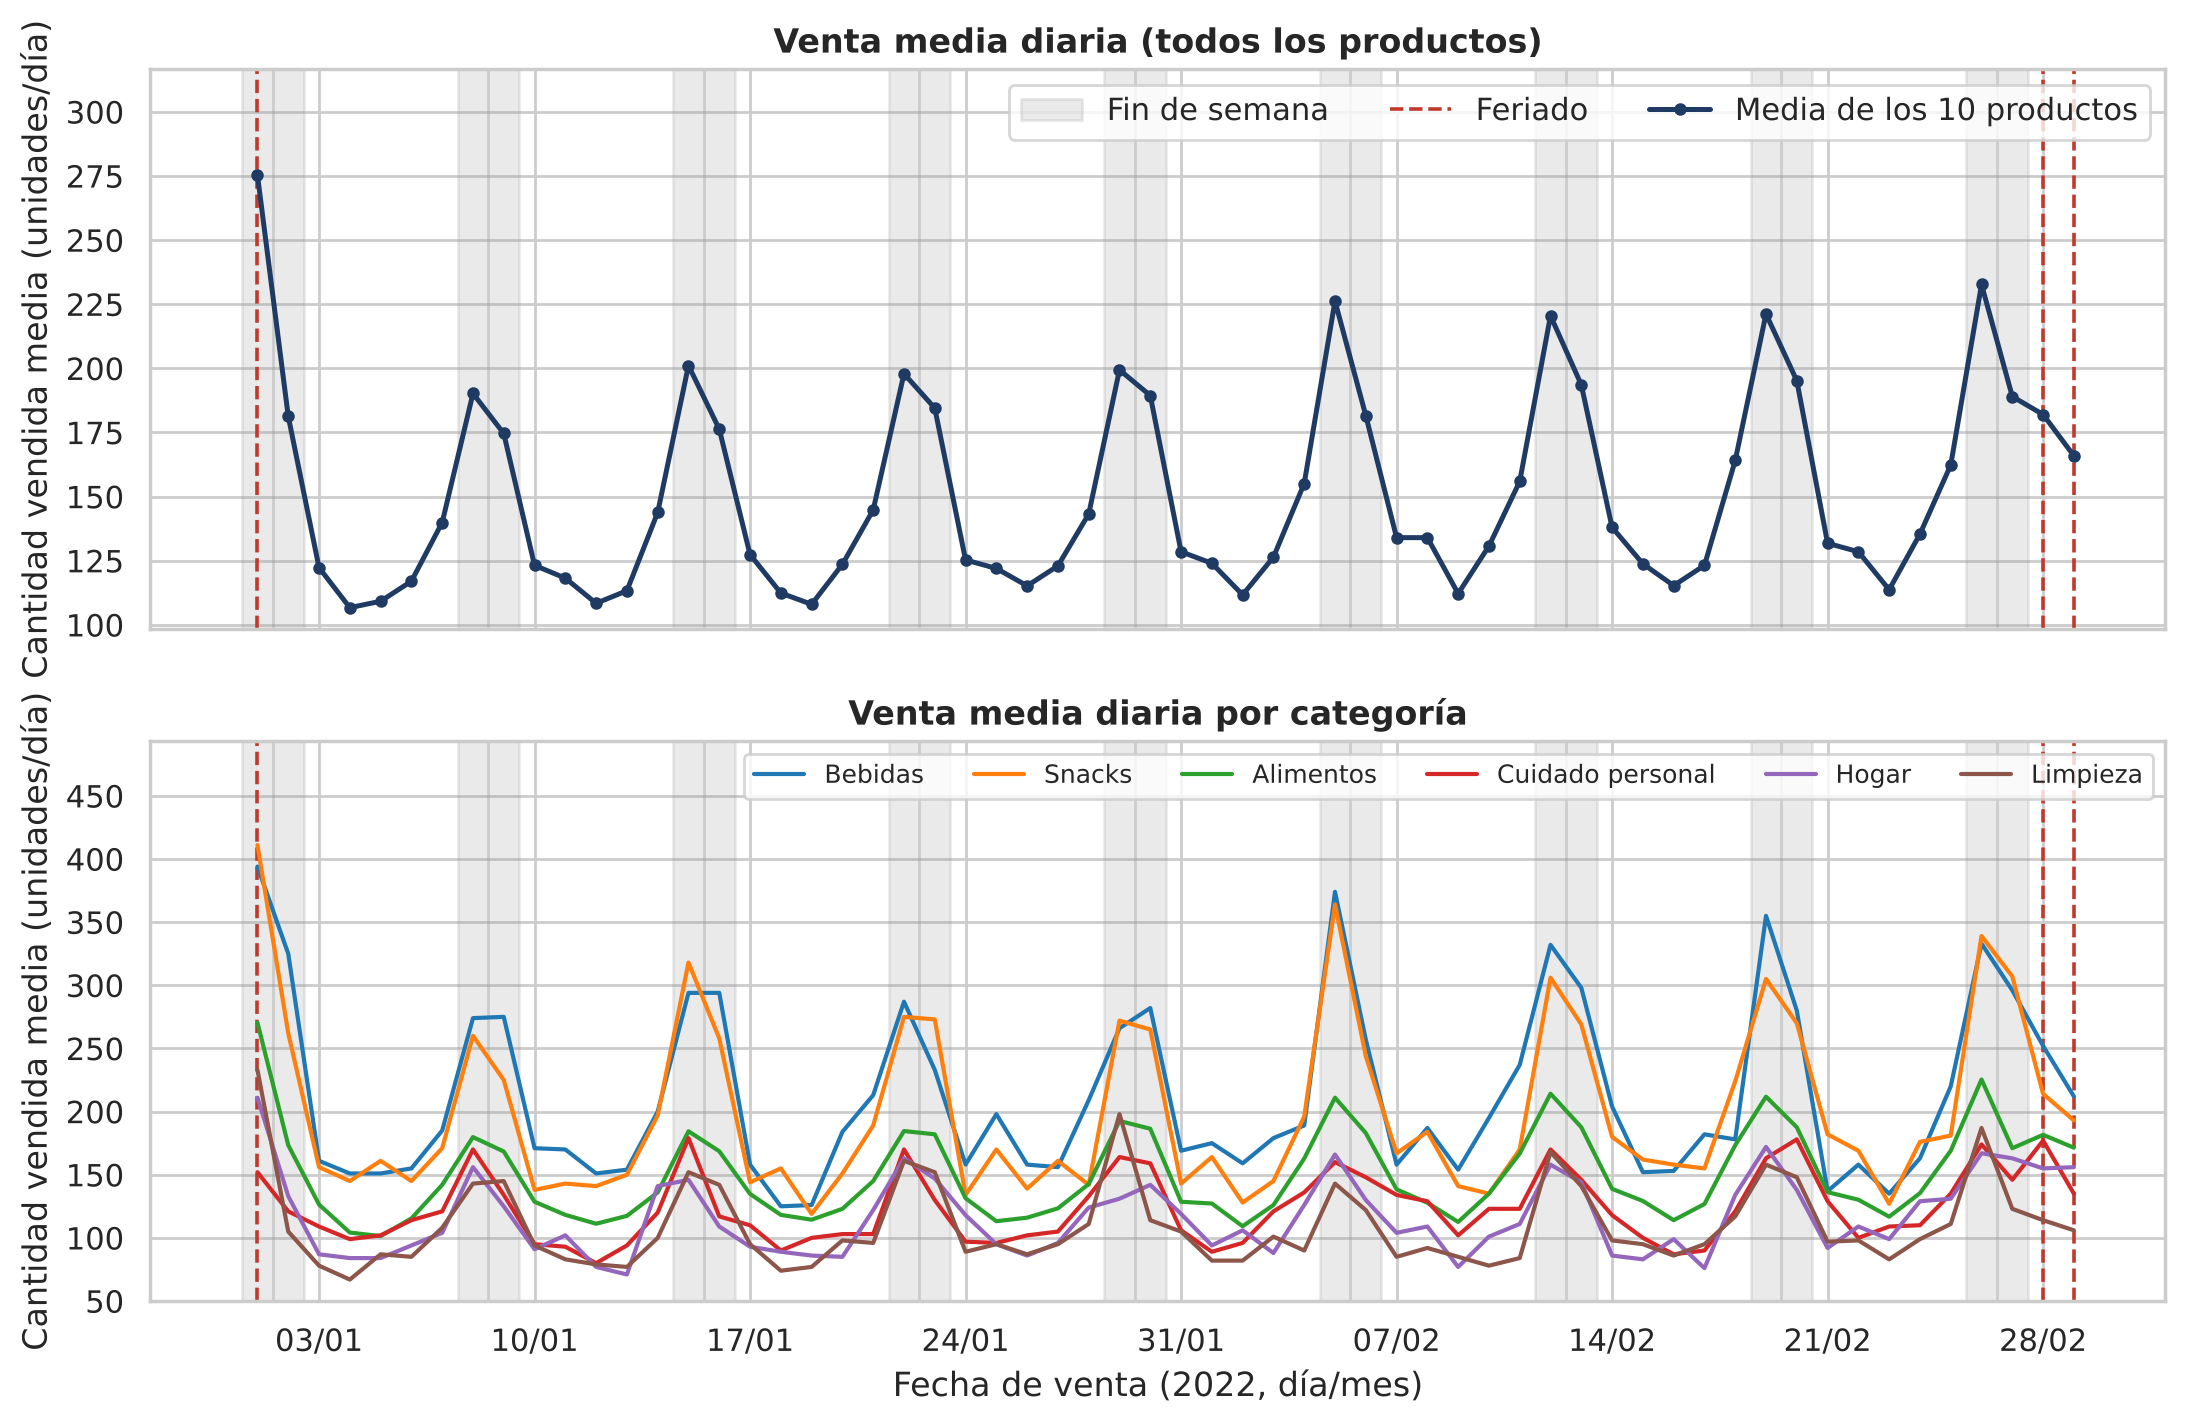

In [6]:
diario = df.groupby("fecha_venta")["cantidad_vendida"].mean()
por_categoria_dia = df.groupby(["fecha_venta", "categoria"])["cantidad_vendida"].mean().unstack()
fines_de_semana = diario.index[diario.index.dayofweek >= 5]
feriados = df.loc[df["es_feriado"] == 1, "fecha_venta"].drop_duplicates().sort_values()

fig, ejes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for i, ax in enumerate(ejes):
    for j, dia in enumerate(fines_de_semana):
        ax.axvspan(dia - pd.Timedelta(hours=12), dia + pd.Timedelta(hours=12), color="#999999", alpha=0.2,
                   label="Fin de semana" if (i == 0 and j == 0) else None)
    for j, dia in enumerate(feriados):
        ax.axvline(dia, color="#c0392b", ls="--", lw=1.3, label="Feriado" if (i == 0 and j == 0) else None)

ejes[0].plot(diario.index, diario.values, marker="o", ms=3.5, lw=1.8, color="#1f3b63", label="Media de los 10 productos")
ejes[0].set(title="Venta media diaria (todos los productos)", ylabel="Cantidad vendida media (unidades/día)", ylim=(None, diario.max() * 1.15))
ejes[0].legend(loc="upper right", ncol=3)

for categoria in ORDEN_CAT:
    ejes[1].plot(por_categoria_dia.index, por_categoria_dia[categoria], lw=1.5, color=PALETA[categoria], label=categoria)
ejes[1].set(title="Venta media diaria por categoría", xlabel="Fecha de venta (2022, día/mes)", ylabel="Cantidad vendida media (unidades/día)",
            ylim=(None, por_categoria_dia.max().max() * 1.2))
ejes[1].legend(ncol=6, loc="upper right", fontsize=9)
ejes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ejes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))

guardar(fig, "eda_temporal.png")
plt.show()

Interpretación: la estacionalidad semanal es muy clara. Las ventas suben cada semana hacia el fin de semana (pico el sábado, algo menos el domingo) y caen a su mínimo a mitad de semana. No hay una tendencia marcada en los 60 días, solo un leve aumento de los picos en febrero (unos 220 a 230 unidades por día de media) frente a enero (unos 190 a 200). El 1 de enero, que fue sábado y feriado, es el día más alto del periodo (unos 275). Todas las categorías siguen la misma forma con niveles distintos: Bebidas y Snacks arriba, Limpieza y Hogar abajo. Los feriados (1 de enero, 28 de febrero y 1 de marzo) caen justo al inicio y al final del periodo, y eso tiene consecuencias que vemos en 3.7. Como el patrón es semanal, `ventas_hace_7_dias` (la venta del mismo día de la semana anterior) es muy informativa: es la predictora más correlacionada con el target (3.6).

## 3. Features y split

Esta sección define qué entra al modelo y cómo se divide el dataset. La regla de oro del plan es que ninguna variable puede contener información del futuro ni del target, y todo lo que sigue está pensado para cumplirla. También para que R2, R3 y R4 usen `X_train`, `X_test`, `y_train`, `y_test` y `COLUMNAS` sin modificarlos.

### 3.1 Definición de variables (`NUM`, `CAT`, `TARGET`)

- Numéricas (11): calendario (`mes`, `dia_del_mes`, `dia_semana`, `es_fin_de_semana`, `es_feriado`, `semana_del_periodo`), rezagos de ventas (`ventas_dia_anterior`, `ventas_hace_7_dias`, `promedio_movil_7d`), `stock_en_momento` y `dias_para_expirar`.
- Categóricas (2, one-hot): `categoria` y `product_id`.
- Target: `cantidad_vendida`.

Cada una de las 22 columnas del CSV queda clasificada en la tabla de abajo: predictora, target o excluida con su motivo. La celda verifica con `assert` que los motivos de exclusión se cumplen en los datos, para que no queden como simples afirmaciones.

In [7]:
NUM = [
    "mes", "dia_del_mes", "dia_semana", "es_fin_de_semana", "es_feriado",
    "semana_del_periodo", "ventas_dia_anterior", "ventas_hace_7_dias",
    "promedio_movil_7d", "stock_en_momento", "dias_para_expirar",
]
CAT = ["categoria", "product_id"]
TARGET = "cantidad_vendida"

# Verificación de los motivos de exclusión contra los datos
assert df["anio"].nunique() == 1                                              # anio es constante
assert (df.groupby("product_id")["stock_actual"].nunique() == 1).all()        # stock_actual: una constante por producto
assert df.groupby("product_id")["nombre"].nunique().eq(1).all() and df.groupby("nombre")["product_id"].nunique().eq(1).all()
assert df.groupby("product_id")["unidad"].nunique().eq(1).all()
assert df.groupby("dia_semana")["nombre_dia"].nunique().eq(1).all() and df.groupby("nombre_dia")["dia_semana"].nunique().eq(1).all()
assert df.groupby(["es_fin_de_semana", "es_feriado"])["tipo_dia"].nunique().eq(1).all()

MOTIVOS = {
    # --- predictoras numéricas
    "mes": "Calendario (nivel mensual).",
    "dia_del_mes": "Calendario (posición dentro del mes).",
    "dia_semana": "Patrón semanal: sábado y domingo venden más (sección 2.3).",
    "es_fin_de_semana": "Indicador binario del patrón semanal.",
    "es_feriado": "Efecto de feriados (ver 3.7: no hay feriados en el train).",
    "semana_del_periodo": "Posición dentro del periodo observado.",
    "ventas_dia_anterior": "Rezago de 1 día: usa solo el pasado (verificado en 3.6).",
    "ventas_hace_7_dias": "Rezago semanal: usa solo el pasado. Sus 70 nulos se resuelven eliminando filas (2.2).",
    "promedio_movil_7d": "Media de los días previos, sin incluir el día actual (verificado en 3.6).",
    "stock_en_momento": "Inventario al iniciar el día, antes de las ventas del día (verificado en 3.6).",
    "dias_para_expirar": "Cuenta regresiva de caducidad del producto.",
    # --- predictoras categóricas
    "categoria": "Categoría del producto (one-hot). Se usa como predictora, no como target.",
    "product_id": "Identifica el producto, que es la principal fuente de diferencia de nivel (one-hot).",
    # --- target
    "cantidad_vendida": "Variable a predecir (continua, unidades/día).",
    # --- excluidas
    "stock_actual": "Constante por producto: solo identifica al producto (huella) y no aporta señal; con ella el modelo reconocería productos, no ventas.",
    "nombre": "Texto en correspondencia 1 a 1 con product_id (redundante).",
    "unidad": "Texto fijo por producto (kg, litro…): redundante con product_id.",
    "fecha_venta": "Se usa para ordenar y dividir en train/test; no es predictora (el calendario ya está en mes, dia_semana, etc.).",
    "anio": "Constante: todo el dataset es 2022.",
    "nombre_dia": "Texto equivalente a dia_semana (1 a 1).",
    "tipo_dia": "Texto determinado por es_fin_de_semana y es_feriado (redundante).",
    "semana_iso": "Redundante con mes, dia_del_mes y semana_del_periodo; además el 1-ene-2022 cae en la semana ISO 52 del año anterior, lo que rompe el orden creciente.",
}
ROL = {c: "Predictora numérica" for c in NUM} | {c: "Predictora categórica (one-hot)" for c in CAT} | {TARGET: "Target"}

tabla_variables = pd.DataFrame(
    {"variable": df.columns, "rol": [ROL.get(c, "Excluida") for c in df.columns]}
)
tabla_variables["motivo"] = tabla_variables["variable"].map(MOTIVOS)

assert tabla_variables["motivo"].notna().all()                  # cada columna tiene una justificación escrita
assert set(MOTIVOS) == set(df.columns)                          # y no sobra ninguna
assert len(NUM) == 11 and len(CAT) == 2

EXCLUIDAS = [c for c in df.columns if c not in NUM + CAT + [TARGET]]
tabla_variables = tabla_variables.set_index("variable").loc[NUM + CAT + [TARGET] + EXCLUIDAS].reset_index()
tabla_variables.to_csv("resultados/tabla_variables.csv", index=False)
tabla_variables

,variable,rol,motivo
0,mes,Predictora numérica,Calendario (nivel mensual).
1,dia_del_mes,Predictora numérica,Calendario (posición dentro del mes).
2,dia_semana,Predictora numérica,Patrón semanal: sábado y domingo venden más (s...
3,es_fin_de_semana,Predictora numérica,Indicador binario del patrón semanal.
4,es_feriado,Predictora numérica,Efecto de feriados (ver 3.7: no hay feriados e...
5,semana_del_periodo,Predictora numérica,Posición dentro del periodo observado.
6,ventas_dia_anterior,Predictora numérica,Rezago de 1 día: usa solo el pasado (verificad...
7,ventas_hace_7_dias,Predictora numérica,Rezago semanal: usa solo el pasado. Sus 70 nul...
8,promedio_movil_7d,Predictora numérica,"Media de los días previos, sin incluir el día ..."
9,stock_en_momento,Predictora numérica,"Inventario al iniciar el día, antes de las ven..."


### 3.2 Eliminación de filas con nulos

Aplicamos la decisión de 2.2: `dropna` sobre las predictoras numéricas y el target. Desde esta celda `df` es el dataset limpio (igual que en el plan) y `df_crudo` conserva las 600 filas originales para las verificaciones de fuga.

In [8]:
df_crudo = df
df = df_crudo.dropna(subset=NUM + [TARGET]).reset_index(drop=True)

assert len(df) == 530
assert df[NUM + [TARGET]].notna().all().all()
assert (df.groupby("product_id").size() == 53).all()

pd.DataFrame(
    {
        "filas": [len(df_crudo), len(df), len(df_crudo) - len(df)],
        "primer día": [df_crudo["fecha_venta"].min().date(), df["fecha_venta"].min().date(), ""],
        "último día": [df_crudo["fecha_venta"].max().date(), df["fecha_venta"].max().date(), ""],
    },
    index=["antes del dropna", "después del dropna", "eliminadas"],
)

,filas,primer día,último día
antes del dropna,600,2022-01-01,2022-03-01
después del dropna,530,2022-01-08,2022-03-01
eliminadas,70,,


### 3.3 Matriz `X` y vector `y` (one-hot)

El SVR solo trabaja con números, así que `categoria` y `product_id` se convierten en columnas de 0 y 1 (*one-hot encoding*). Con `drop_first=True` nos ahorramos una categoría de referencia redundante: Alimentos y P0001 quedan implícitas cuando todas las demás columnas valen 0. Esperamos 11 numéricas, 5 dummies de `categoria` y 9 dummies de `product_id`, es decir, 25 columnas.

También verificamos que `X` no tenga nulos, que todas las columnas sean numéricas, que ninguna sea constante y que el target no se haya colado entre las predictoras.

In [9]:
X = pd.get_dummies(df[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
y = df[TARGET]

assert X.shape == (530, 25)
assert X.isna().sum().sum() == 0 and y.isna().sum() == 0
assert X.select_dtypes(include="number").shape[1] == X.shape[1]   # todas las columnas son numéricas
assert (X.nunique() > 1).all()
assert TARGET not in X.columns

pd.DataFrame(
    {
        "columnas": [len(NUM), X.filter(like="categoria_").shape[1], X.filter(like="product_id_").shape[1], X.shape[1]],
        "ejemplos": [
            ", ".join(NUM[:3]) + ", …",
            ", ".join(X.filter(like="categoria_").columns[:2]) + ", …",
            ", ".join(X.filter(like="product_id_").columns[:2]) + ", …",
            "",
        ],
    },
    index=["numéricas", "dummies de categoria", "dummies de product_id", "total en X"],
)

,columnas,ejemplos
numéricas,11,"mes, dia_del_mes, dia_semana, …"
dummies de categoria,5,"categoria_Bebidas, categoria_Cuidado personal, …"
dummies de product_id,9,"product_id_P0002, product_id_P0003, …"
total en X,25,


### 3.4 Split temporal 80/20 y lista `COLUMNAS`

El split es temporal, no aleatorio: el 80 % de las fechas más antiguas va a *train* y el resto a *test*. Con un split aleatorio, el entrenamiento incluiría días vecinos del día que luego hay que predecir (por ejemplo, un lunes de train justo antes de un martes de test) y las métricas saldrían infladas. Con el split temporal simulamos lo que pasa en la práctica: predecir el futuro con el pasado.

El corte es el cuantil 0,8 de `fecha_venta` y se hace por días completos, así que los 10 productos entran juntos en cada día. `COLUMNAS` guarda el orden exacto de las columnas de `X_train`; R3 lo necesita en `predecir_venta()` para alinear un sample nuevo.

In [10]:
corte = df["fecha_venta"].quantile(0.8)
es_train = df["fecha_venta"] <= corte

X_train, y_train = X[es_train], y[es_train]
X_test, y_test = X[~es_train], y[~es_train]
COLUMNAS = X_train.columns.tolist()

fechas_train, fechas_test = df.loc[es_train, "fecha_venta"], df.loc[~es_train, "fecha_venta"]
assert fechas_train.max() < fechas_test.min()                               # sin solapamiento temporal
assert len(X_train) + len(X_test) == len(X)
assert set(df.loc[es_train, "product_id"]) == set(df.loc[~es_train, "product_id"])   # los 10 productos están en ambos
assert abs(len(X_train) / len(X) - 0.8) < 0.02                              # proporción ≈ 80/20
assert COLUMNAS == X_test.columns.tolist() and len(COLUMNAS) == 25

pd.DataFrame(
    {
        "filas": [len(X_train), len(X_test)],
        "% de filas": [round(len(X_train) / len(X) * 100, 1), round(len(X_test) / len(X) * 100, 1)],
        "primer día": [fechas_train.min().date(), fechas_test.min().date()],
        "último día": [fechas_train.max().date(), fechas_test.max().date()],
        "días": [fechas_train.nunique(), fechas_test.nunique()],
        "productos": [df.loc[es_train, "product_id"].nunique(), df.loc[~es_train, "product_id"].nunique()],
    },
    index=["train", "test"],
)

,filas,% de filas,primer día,último día,días,productos
train,430,81.1,2022-01-08,2022-02-19,43,10
test,100,18.9,2022-02-20,2022-03-01,10,10


### 3.5 Visualización del split

Graficamos la venta media diaria por conjunto junto con la fecha de corte, para comprobar a simple vista que *train* es el pasado y *test* el futuro.

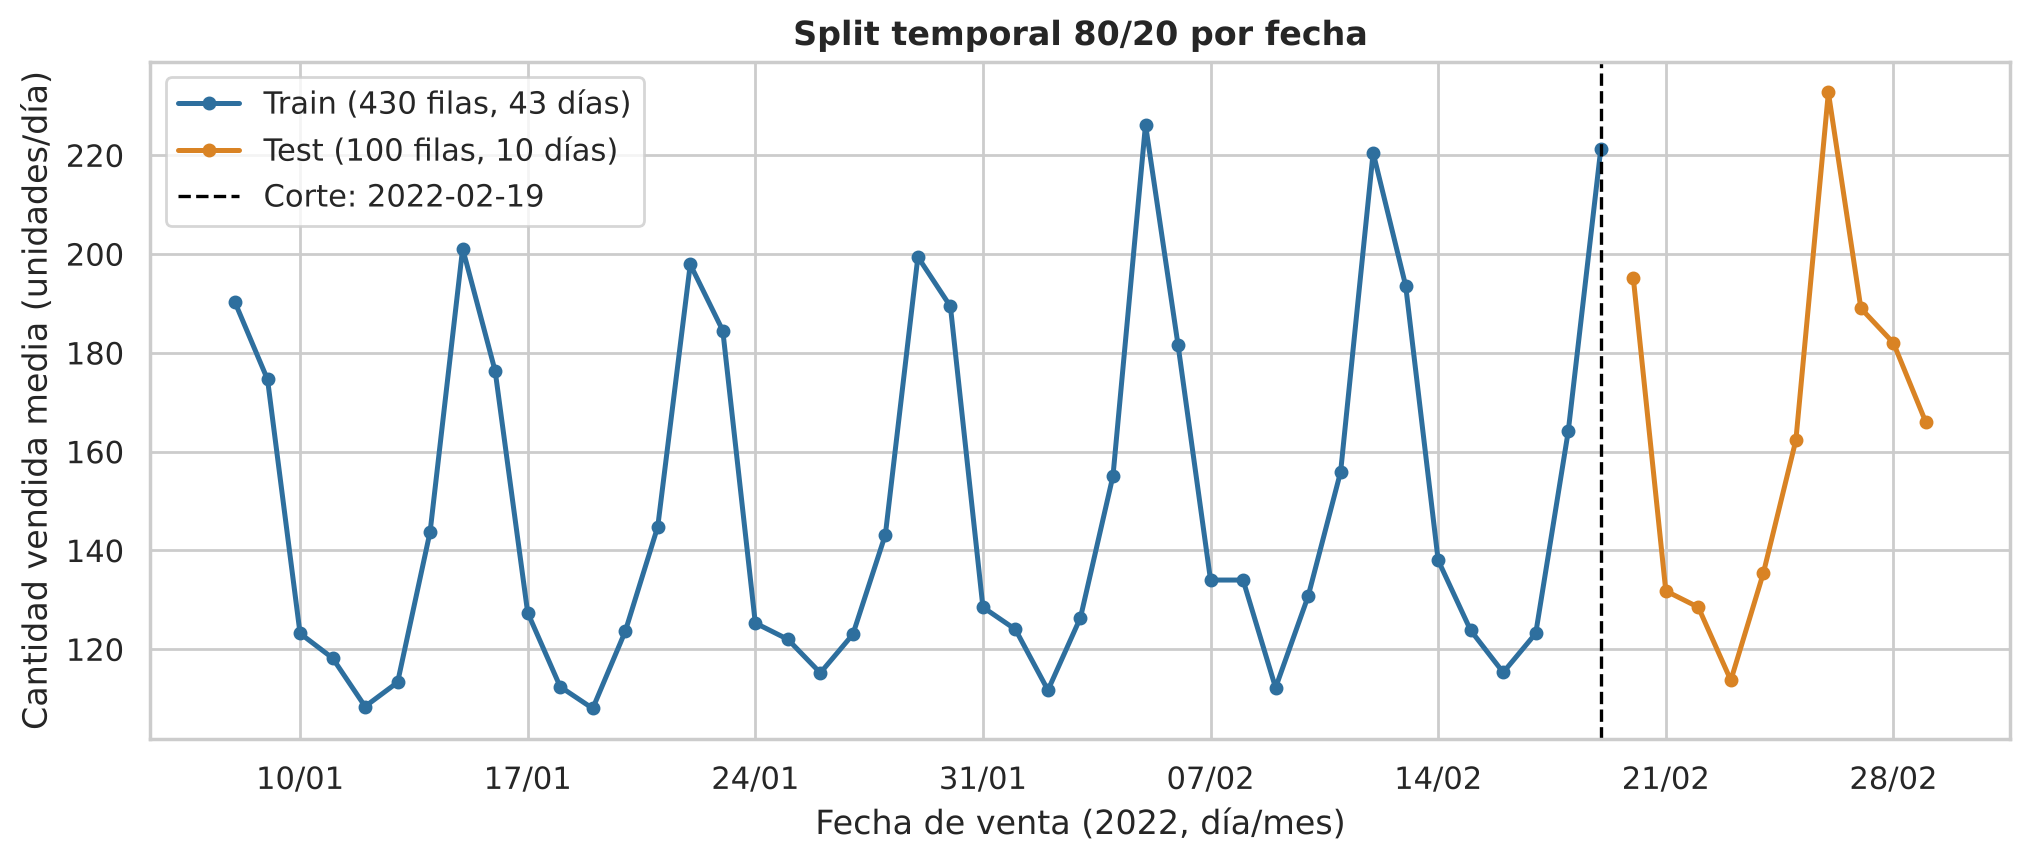

In [11]:
venta_por_dia = (
    df.assign(conjunto=np.where(es_train, "Train", "Test"))
    .groupby(["fecha_venta", "conjunto"], as_index=False)["cantidad_vendida"].mean()
)
colores = {"Train": "#2e6f9e", "Test": "#d98324"}

fig, ax = plt.subplots(figsize=(12, 4.4))
for conjunto, color in colores.items():
    parte = venta_por_dia[venta_por_dia["conjunto"] == conjunto]
    n_filas = len(X_train) if conjunto == "Train" else len(X_test)
    ax.plot(parte["fecha_venta"], parte["cantidad_vendida"], marker="o", ms=4, lw=1.8, color=color,
            label=f"{conjunto} ({n_filas} filas, {parte['fecha_venta'].nunique()} días)")
ax.axvline(corte, color="black", ls="--", lw=1.2, label=f"Corte: {corte.date()}")
ax.set(title="Split temporal 80/20 por fecha", xlabel="Fecha de venta (2022, día/mes)", ylabel="Cantidad vendida media (unidades/día)")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.legend(loc="upper left")
guardar(fig, "split_temporal.png")
plt.show()

### 3.6 Revisión de fuga de información

Queremos comprobar con cálculos, y no solo afirmar, que ninguna predictora contiene información del futuro ni del target. Cada control da `True` o `False` y la celda falla (`assert`) si alguno no se cumple. Los controles son:

1. Rezagos: `ventas_dia_anterior` debe ser la venta del día previo y `ventas_hace_7_dias` la de 7 días antes. Si coinciden, solo miran el pasado.
2. Promedio móvil: `promedio_movil_7d` debe ser la media de hasta 7 días previos, sin incluir el día actual. Lo contrastamos con la versión que sí lo incluiría, que no debe coincidir.
3. Stock: `stock_en_momento` del día *d* debe ser el stock del día anterior menos las ventas del día anterior, o más si hubo reposición. Nunca debe quedar por debajo, porque eso indicaría que ya descuenta las ventas del propio día *d*.
4. Exclusiones y target: `stock_actual` es constante por producto (identifica al producto y por eso se excluye) y el target no está en `X`.
5. Correlación sospechosa: ninguna predictora debe tener |r| ≥ 0,95 con el target, porque un valor casi perfecto sería señal de fuga.
6. Split: todas las fechas de *train* son anteriores a las de *test*.

In [12]:
ordenado = df_crudo.sort_values(["product_id", "fecha_venta"])
ventas = ordenado.groupby("product_id")["cantidad_vendida"]


def coincide(columna, esperado):
    """True si la columna vale lo esperado y los nulos están en las mismas filas."""
    presentes = ordenado[columna].notna()
    mismos_nulos = np.array_equal(ordenado[columna].isna().to_numpy(), esperado.isna().to_numpy())
    return mismos_nulos and bool(np.allclose(ordenado.loc[presentes, columna], esperado[presentes]))


media_solo_previos = ventas.transform(lambda s: s.shift(1).rolling(7, min_periods=1).mean())
media_con_hoy = ventas.transform(lambda s: s.rolling(7, min_periods=1).mean())

stock_esperado = ordenado.groupby("product_id")["stock_en_momento"].shift(1) - ventas.shift(1)
dif_stock = (ordenado["stock_en_momento"] - stock_esperado).dropna()
pct_stock_exacto = (dif_stock == 0).mean() * 100

corr_con_target = df[NUM].corrwith(df[TARGET]).abs().sort_values(ascending=False)

controles = pd.DataFrame(
    [
        ("ventas_dia_anterior = ventas del día previo", coincide("ventas_dia_anterior", ventas.shift(1)),
         "Coincide en todas las filas con valor"),
        ("ventas_hace_7_dias = ventas de 7 días antes", coincide("ventas_hace_7_dias", ventas.shift(7)),
         "Coincide en todas las filas con valor"),
        ("promedio_movil_7d usa solo días previos", coincide("promedio_movil_7d", media_solo_previos),
         "Media de hasta 7 días anteriores al día actual"),
        ("promedio_movil_7d NO incluye el día actual", not coincide("promedio_movil_7d", media_con_hoy),
         "La versión que incluye el día actual no coincide"),
        ("stock_en_momento no descuenta las ventas del propio día", bool((dif_stock >= 0).all()),
         f"{pct_stock_exacto:.0f}% = stock previo − ventas previas; el resto son reposiciones (stock mayor)"),
        ("stock_actual es constante por producto (excluida)", bool((df_crudo.groupby("product_id")["stock_actual"].nunique() == 1).all()),
         "Solo identifica al producto"),
        ("El target no está en X", TARGET not in X.columns, ""),
        ("Ninguna predictora con |r| ≥ 0,95 con el target", bool(corr_con_target.max() < 0.95),
         f"Máxima: {corr_con_target.index[0]} (|r| = {corr_con_target.iloc[0]:.2f})"),
        ("Fechas de train anteriores a las de test", bool(fechas_train.max() < fechas_test.min()),
         f"{fechas_train.max().date()} < {fechas_test.min().date()}"),
    ],
    columns=["control", "cumple", "detalle"],
)
assert controles["cumple"].all(), "Hay un control de fuga que no se cumple"
controles.assign(cumple=controles["cumple"].map({True: "✔", False: "✘"}))

,control,cumple,detalle
0,ventas_dia_anterior = ventas del día previo,✔,Coincide en todas las filas con valor
1,ventas_hace_7_dias = ventas de 7 días antes,✔,Coincide en todas las filas con valor
2,promedio_movil_7d usa solo días previos,✔,Media de hasta 7 días anteriores al día actual
3,promedio_movil_7d NO incluye el día actual,✔,La versión que incluye el día actual no coincide
4,stock_en_momento no descuenta las ventas del p...,✔,72% = stock previo − ventas previas; el resto ...
5,stock_actual es constante por producto (excluida),✔,Solo identifica al producto
6,El target no está en X,✔,
7,"Ninguna predictora con |r| ≥ 0,95 con el target",✔,Máxima: ventas_hace_7_dias (|r| = 0.89)
8,Fechas de train anteriores a las de test,✔,2022-02-19 < 2022-02-20


Resultado: los tres rezagos usan solo días previos y `stock_en_momento` es el inventario al inicio del día, así que ninguna variable usa información del futuro ni del target del propio día. La correlación más alta con el target es la de `ventas_hace_7_dias`. Es esperable porque el patrón de ventas se repite cada semana, y queda por debajo del umbral de sospecha.

Un detalle: en las filas de *test*, los rezagos usan las ventas reales de los días anteriores, incluidos los últimos días de *train*. Eso es válido porque en la práctica también se conocen las ventas de ayer, pero significa que el modelo hace una predicción a un día con historial real y no un pronóstico de varios días hacia adelante. Hay que tenerlo presente al comparar con el LSTM de la práctica 001.

### 3.7 Diagnóstico para el equipo: rangos en train y test

Con un split temporal, algunas variables que avanzan con el tiempo toman en *test* valores que no existieron en *train*, y un SVR no extrapola bien fuera del rango que vio. Conviene saberlo antes de modelar. La tabla mide, para cada variable, qué porcentaje de las filas de *test* queda fuera del rango de *train*. Además buscamos columnas de `X` que estén duplicadas entre sí.

In [13]:
VARIABLES_EN_RIESGO = ["es_feriado", "mes", "semana_del_periodo", "dias_para_expirar", "stock_en_momento", "dia_del_mes"]
filas_riesgo = []
for variable in VARIABLES_EN_RIESGO:
    en_train, en_test = X_train[variable], X_test[variable]
    fuera = ((en_test < en_train.min()) | (en_test > en_train.max())).mean() * 100
    filas_riesgo.append(
        {
            "variable": variable,
            "rango en train": f"{en_train.min():g} a {en_train.max():g}",
            "rango en test": f"{en_test.min():g} a {en_test.max():g}",
            "% de test fuera del rango de train": round(fuera, 1),
        }
    )
display(pd.DataFrame(filas_riesgo).set_index("variable"))

huellas = {}
for columna in X.columns:
    huellas.setdefault(tuple(X[columna]), []).append(columna)
duplicadas = [grupo for grupo in huellas.values() if len(grupo) > 1]
pd.DataFrame(duplicadas, columns=["columna A", "columna B"]).rename_axis("par")

,rango en train,rango en test,% de test fuera del rango de train
variable,,,
es_feriado,0 a 0,0 a 1,20.0
mes,1 a 2,2 a 3,10.0
semana_del_periodo,2 a 8,8 a 9,40.0
dias_para_expirar,82 a 383,72 a 340,10.0
stock_en_momento,259 a 799,290 a 799,0.0
dia_del_mes,1 a 31,1 a 28,0.0


,columna A,columna B
par,,
0,categoria_Bebidas,product_id_P0008
1,categoria_Cuidado personal,product_id_P0007
2,categoria_Hogar,product_id_P0010
3,categoria_Limpieza,product_id_P0006
4,categoria_Snacks,product_id_P0009


Hallazgos para el equipo. No cambian las decisiones cerradas del plan, pero R2 y R4 deberían conocerlos.

1. `es_feriado` no varía en *train*. Los feriados del dataset son el 1 de enero, el 28 de febrero y el 1 de marzo. El 1 de enero desaparece con los nulos y los otros dos caen en *test* (20 de las 100 filas), así que en *train* la columna vale siempre 0 y el SVR no puede aprender el efecto de un feriado. (`StandardScaler` no falla con una columna constante, solo la deja sin información.) En la práctica, el caso de demanda alta de `predecir_venta()`, con `es_feriado = 1`, no se verá influido por esa variable, y las métricas de los dos días feriados de *test* miden extrapolación. Conviene decirlo en las limitaciones (R4) y armar el caso alto con fin de semana y rezagos altos (R3).
2. Algunas variables que avanzan con el tiempo salen del rango de *train*: `mes` (10 % de *test*, el 1 de marzo), `semana_del_periodo` (40 %, la semana 9) y `dias_para_expirar` (10 %; es una cuenta regresiva que baja 1 por día). El modelo nunca vio esos valores. Es inevitable en un split temporal con solo 53 días útiles. Un kernel RBF tiende a volver hacia la media lejos de los datos de entrenamiento y uno lineal extrapola en línea recta, algo que R2 y R4 pueden usar para explicar diferencias entre kernels y para interpretar la importancia de estas variables.
3. Hay cinco pares de columnas idénticas. `categoria_Bebidas`, `categoria_Cuidado personal`, `categoria_Hogar`, `categoria_Limpieza` y `categoria_Snacks` son iguales, fila por fila, a la dummy de su único producto, así que `categoria` solo aporta información propia para Alimentos (5 productos). No es un error y el plan define ambas como predictoras, pero esas columnas duplicadas cuentan dos veces en la distancia del kernel RBF y refuerzan el peso de la identidad del producto.
4. `semana_iso` no aparece en la tabla de exclusiones del plan. La excluimos (el motivo está en 3.1) y conviene agregarla a la sección 3.1 del documento del plan.
5. El *test* es pequeño: 100 filas, que son 10 días (3 de ellos de fin de semana) por 10 productos. Las métricas de *test* serán ruidosas, como ya anticipa el plan, así que R2 debería reportar también el RMSE de validación cruzada.

### 3.8 Decisiones de limpieza y entrega a R2

Decisiones de limpieza (R1):

| # | Decisión | Justificación |
|---|---|---|
| 1 | Eliminar las 70 filas con nulos (de 600 a 530) en lugar de imputar | Los nulos son rezagos al inicio de cada producto, e imputarlos inventaría ventas. Quedan 53 días completos por producto. |
| 2 | Excluir `stock_actual`, `nombre`, `unidad`, `fecha_venta`, `anio`, `nombre_dia`, `tipo_dia` y `semana_iso` | Son constantes, textos redundantes o identificadores del producto. El motivo de cada una está en la tabla de 3.1 y se verificó con los datos. |
| 3 | `categoria` y `product_id` como predictoras (one-hot, `drop_first=True`), no como target | Con `categoria` como target el modelo solo identifica productos (el F1-macro depende de columnas que son la huella del producto). |
| 4 | Split temporal 80/20 por fecha (corte en el cuantil 0,8) | Evita fuga entre días consecutivos y simula predecir el futuro. |
| 5 | Sin escalado en esta sección | El `StandardScaler` de `X` y de `y` va dentro del *pipeline* (R2), ajustado solo con *train*, para no filtrar información de *test*. |

Contrato con R2, R3 y R4: entregamos sin modificar `X_train`, `X_test`, `y_train`, `y_test`, `COLUMNAS`, `df` (limpio), `SEED` y `guardar()`. La celda siguiente comprueba los criterios de aceptación del plan: que existan, que no tengan nulos y que la proporción temporal sea la esperada.

In [14]:
contrato = pd.DataFrame(
    {
        "forma": [str(o.shape) for o in (X_train, X_test, y_train, y_test)],
        "nulos": [int(np.asarray(o.isna()).sum()) for o in (X_train, X_test, y_train, y_test)],
        "% del total": [round(len(o) / len(X) * 100, 1) for o in (X_train, X_test, y_train, y_test)],
    },
    index=["X_train", "X_test", "y_train", "y_test"],
)
assert (contrato["nulos"] == 0).all()
assert len(COLUMNAS) == X_train.shape[1] == X_test.shape[1] == 25
contrato

,forma,nulos,% del total
X_train,"(430, 25)",0,81.1
X_test,"(100, 25)",0,18.9
y_train,"(430,)",0,81.1
y_test,"(100,)",0,18.9
